# Notebook 13 — Đối chứng ngân sách exact trên choice: 80 → 200

Chỉ chạy **2 lượt exact** từ hai khởi tạo ban đầu. Giữ p=1, penalty (3,3), Hamiltonian chuẩn hóa, COBYLA, ngưỡng dừng và 1.024 shots cuối. Đối chiếu trực tiếp report notebook 12 đã chạy trên Windows; không tối ưu lại reference hoặc sampled.

Đây là **chạy lại từ đầu với giới hạn mới**, không tiếp tục trạng thái nội bộ COBYLA. `maxiter=200` là trần số đánh giá; optimizer có thể dừng sớm. Không chọn góc theo P_opt sau khi xem kết quả. Mỗi khởi tạo chỉ có một lượt exact, chưa đủ cho kết luận thống kê hay cực tiểu toàn cục.

Hướng dẫn: `docs/qaoa_exact_budget.md`.

## Bước 1 — Kernel và module
Restart Kernel sau khi cập nhật. Dùng môi trường notebook 12 để so sánh cùng phiên bản; notebook sẽ hiển thị mọi khác biệt runtime.

In [1]:
from pathlib import Path
import sys, json, hashlib, zipfile
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, psutil
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / "src/qubo.py").is_file(): ROOT = ROOT.parent
if not (ROOT / "src/qubo.py").is_file(): raise RuntimeError("Mở notebook từ repo nt409-task-placement.")
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.qubo import build_qubo
from src.qaoa_experiment import prepare_reference, experiment_environment, _MemoryMonitor
from src.convergence_diagnostics import ExactQAOAOracle, run_exact_qaoa
from src.convergence_campaign import make_design, make_trials, new_campaign, save_campaign, verify_campaign, record_trial
assert tuple(map(int, scipy.__version__.split('.')[:2])) >= (1,16)
print("Python:",sys.executable)
print(json.dumps(experiment_environment()["runtime"],indent=2))

Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
{
  "python_version": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy_version": "2.5.3",
  "scipy_version": "1.18.1",
  "qiskit_version": "2.5.2",
  "qiskit_optimization_version": "0.7.0",
  "qiskit_aer_version": "0.17.2"
}


## Bước 2 — Chọn baseline và ngân sách
Baseline mặc định là manifest choice bạn đã chạy ngày 08/10. Gói cập nhật có bản sao nguyên vẹn của manifest và 8 report nguồn.

Chỉ điền `RESUME_MANIFEST` khi một đợt **notebook 13** bị ngắt. Không dùng manifest notebook 12 để resume với maxiter mới. Một lượt đang chạy bị ngắt phải chạy lại từ đầu; các lượt đã lưu sẽ được bỏ qua.

In [2]:
BASELINE_MANIFEST = "data/reference_results/phase4e_convergence_runs/convergence_p1_choice_20261008T034113505740Z.json"
RESUME_MANIFEST = None
MAX_EVALUATIONS = 200
assert MAX_EVALUATIONS == 200
INSTANCE_ID = "p1_choice"
instance = json.loads((ROOT / "data/instances/p1_choice.json").read_text(encoding="utf-8"))
bundle = build_qubo(instance, assignment_penalty=3, capacity_penalty=3)
reference = prepare_reference(bundle)

def file_digest(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def notebook_digest(path):
    nb=json.loads(Path(path).read_text(encoding="utf-8"))
    import re
    sources=[(c["cell_type"],re.sub(r"^RESUME_MANIFEST *=.*$", "RESUME_MANIFEST = None",
              "".join(c["source"]),flags=re.M)) for c in nb["cells"]]
    return hashlib.sha256(json.dumps(sources,ensure_ascii=False).encode()).hexdigest()

def read_baseline():
    old = json.loads((ROOT / BASELINE_MANIFEST).read_text(encoding="utf-8"))
    verified = verify_campaign(ROOT, old, old["design"], bundle, reference,
                               require_current_environment=False)
    assert old["design"]["instance_id"] == INSTANCE_ID
    assert len(verified) == old["planned_run_count"] == 8 and not old["remaining_run_keys"]
    assert old["design"]["base_config"]["maxiter"] == 80
    exact = {r["initial_point_id"]:r for r in verified if r["objective_mode"]=="exact"}
    assert set(exact)=={"common","alternative"}
    assert all(r["cost_function_evals"]==80 and not r["optimizer_success"] for r in exact.values())
    return old, exact
baseline, baseline_exact = read_baseline()
baseline_reports = {k:json.loads((ROOT/r["report"]).read_text(encoding="utf-8")) for k,r in baseline_exact.items()}
display(pd.DataFrame([dict(start=k,E_80=r["exact_mean_qubo_energy"],
    P_opt_80_percent=100*r["exact_optimal_probability"],stop=r["optimizer_message"]) for k,r in baseline_exact.items()]))

,start,E_80,P_opt_80_percent,stop
0,common,62.289841,0.133001,Return from COBYLA because the objective funct...
1,alternative,59.319691,0.125555,Return from COBYLA because the objective funct...


## Bước 3 — Cố định hai lượt và kiểm tra khác biệt môi trường
Cấu hình lấy từ baseline, chỉ đổi `maxiter`. Seed cuối giữ 100060 để kiểm soát cấu hình; giữa hai ngân sách đây **không phải batch lặp độc lập mới**. So sánh chất lượng chính dùng kỳ vọng/xác suất lý tưởng; tần suất đo cuối được báo riêng.

Mã mô hình, oracle và optimizer phải khớp baseline. Module quản lý campaign được mở rộng để chọn riêng exact; mọi report vẫn được kiểm tra đầy đủ. Nếu runtime khác, kết quả chỉ là đối chứng khác môi trường, không quy mọi chênh lệch cho ngân sách.

In [3]:
STARTS = baseline["design"]["starts"]
SEEDS = baseline["design"]["seeds"]
BASE_CONFIG = {**baseline["design"]["base_config"], "maxiter":MAX_EVALUATIONS}
design = make_design(instance,bundle,SEEDS,BASE_CONFIG,STARTS,objective_modes=("exact",))
current_env = design["environment"]
old_env = baseline["design"]["environment"]
core_changes, newline_only = [], []
for name, digest in old_env["source_sha256"].items():
    if name == "convergence_campaign.py" or current_env["source_sha256"].get(name)==digest: continue
    raw=(ROOT/"src"/name).read_bytes().replace(bytes([13,10]),bytes([10]))
    newline_hashes={hashlib.sha256(raw).hexdigest(),
                    hashlib.sha256(raw.replace(bytes([10]),bytes([13,10]))).hexdigest()}
    (newline_only if digest in newline_hashes else core_changes).append(name)
print("File chỉ khác LF/CRLF:",newline_only)
if core_changes: raise RuntimeError(f"Mã lõi khác baseline: {core_changes}; cần review trước khi so ngân sách.")
runtime_changes = {k:{"baseline":v,"current":current_env["runtime"].get(k)}
                   for k,v in old_env["runtime"].items() if current_env["runtime"].get(k)!=v}
print("Khác biệt runtime:", json.dumps(runtime_changes,ensure_ascii=False,indent=2))
print("Loại đối chứng:", "khác môi trường" if runtime_changes else "cùng môi trường")
evidence_paths = [BASELINE_MANIFEST]+[r["report"] for r in baseline["completed_runs"]]
design["study"].update(stage="exact_budget_80_vs_200", budget_rule="rerun_original_starts_only_maxiter_changes",
    baseline_design_hash=baseline["design_hash"],
    baseline_files_sha256={p:file_digest(ROOT/p) for p in evidence_paths},
    notebook_sha256=notebook_digest(ROOT/"notebooks/13_qaoa_exact_budget_choice.ipynb"),
    runtime_changes=runtime_changes)
trials = make_trials(design)
assert len(trials)==2 and all(t["objective_mode"]=="exact" for t in trials)
for t in trials:
    old_config=baseline_reports[t["initial_point_id"]]["config"]
    assert {k:v for k,v in t["config"].items() if k!="maxiter"} == {k:v for k,v in old_config.items() if k!="maxiter"}
print("Qubit:",bundle["qubo"].get_num_vars(),"| E_min:",reference["minimum_energy"])
display(pd.DataFrame([dict(arm=t["arm_id"],start=t["config"]["initial_point"],
    maxiter=t["config"]["maxiter"],final_seed=t["config"]["evaluation_seed"],
    final_shots=t["config"]["evaluation_shots"]) for t in trials]))

File chỉ khác LF/CRLF: []
Khác biệt runtime: {}
Loại đối chứng: cùng môi trường
Qubit: 20 | E_min: 1.0


,arm,start,maxiter,final_seed,final_shots
0,exact_common,"[0.3, 1.0]",200,100060,1024
1,exact_alternative,"[0.8, 1.2]",200,100060,1024


## Bước 4 — Đo tài nguyên và kiểm tra lại góc baseline
Oracle đánh giá lại hai góc cuối của baseline: năng lượng và P_opt phải khớp trong sai số số học. Đây là audit, không tính vào số đánh giá optimizer.

Giữ time guard 600 giây/lượt như baseline. Ước lượng không phải cam kết thời gian. Nếu vượt, dừng trước campaign và xem xét tài nguyên; không tự tăng thêm cấu hình.

In [4]:
with _MemoryMonitor() as memory:
    oracle=ExactQAOAOracle(bundle,trials[0]["config"],reference)
    audit=[]
    for start,row in baseline_exact.items():
        stats=oracle.evaluate(row["optimal_point"])
        for key in ("exact_mean_qubo_energy","exact_optimal_probability","exact_ground_probability"):
            assert np.isclose(stats[key],row[key],atol=1e-7,rtol=0), (start,key)
        audit.append(dict(start=start,**stats))
probe_seconds=max(r["simulation_seconds"] for r in audit)
rough_seconds=1.5*probe_seconds*(MAX_EVALUATIONS+2)
print(f"Ước lượng mỗi lượt: {rough_seconds:.1f}s; hai lượt: {2*rough_seconds:.1f}s (chưa gồm toàn bộ hậu xử lý).")
print("RSS MiB:",memory.as_dict()["process_peak_rss_mib"])
if rough_seconds>BASE_CONFIG["max_seconds"]: raise RuntimeError("Ước lượng vượt time guard; kiểm tra tài nguyên trước khi chạy.")
if psutil.virtual_memory().available/2**30<BASE_CONFIG["min_available_gib"]: raise RuntimeError("RAM khả dụng dưới ngưỡng.")
display(pd.DataFrame(audit)[["start","exact_mean_qubo_energy","exact_optimal_probability"]])

Ước lượng mỗi lượt: 18.0s; hai lượt: 35.9s (chưa gồm toàn bộ hậu xử lý).
RSS MiB: 235.87109375


,start,exact_mean_qubo_energy,exact_optimal_probability
0,common,62.289841,0.001330
1,alternative,59.319691,0.001256


## Bước 5 — Tạo hoặc resume campaign 200
Manifest mới có tiền tố `exact_budget_`. Report dùng cùng schema và thư mục phase4e, tên có timestamp riêng. Danh sách report đúng được xác định bằng manifest, không ghép mọi file trong thư mục.

In [5]:
RESULT_DIR=ROOT/"data/reference_results/phase4e_convergence_runs"
if RESUME_MANIFEST is None:
    campaign=new_campaign(design)
    campaign["baseline_audit"]=audit
    MANIFEST_PATH=RESULT_DIR/f"exact_budget_{INSTANCE_ID}_{campaign['campaign_id']}.json"
    save_campaign(MANIFEST_PATH,campaign)
else:
    MANIFEST_PATH=(ROOT/RESUME_MANIFEST).resolve()
    if not MANIFEST_PATH.is_relative_to(ROOT): raise ValueError("Manifest phải nằm trong repo.")
    campaign=json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
verify_campaign(ROOT,campaign,design,bundle,reference)
print("MANIFEST:",MANIFEST_PATH.relative_to(ROOT).as_posix())
print("Hoàn tất:",campaign["completed_run_count"],"/",campaign["planned_run_count"])

MANIFEST: data/reference_results/phase4e_convergence_runs/exact_budget_p1_choice_20261009T080323983169Z.json
Hoàn tất: 0 / 2


## Bước 6 — Chạy hai lượt exact
Chạy từ common [0.3,1.0] và alternative [0.8,1.2], không từ góc cuối cap80. Lượt hoàn tất được lưu kể cả khi không có mẫu tối ưu. Resume không chạy lại lượt đã hoàn tất.

In [6]:
assert BASE_CONFIG=={**baseline["design"]["base_config"],"maxiter":200}
for path,digest in design["study"]["baseline_files_sha256"].items():
    assert file_digest(ROOT/path)==digest, f"Baseline đã đổi: {path}"
verify_campaign(ROOT,campaign,design,bundle,reference)
completed={r["run_key"] for r in campaign["completed_runs"]}
for trial in campaign["planned_runs"]:
    if trial["run_key"] in completed: continue
    print("\nĐang chạy",trial["arm_id"],flush=True)
    report=run_exact_qaoa(bundle,trial["config"],reference,oracle,progress=True)
    if report["status"]!="completed": raise RuntimeError("Lượt chưa hoàn tất; resume sẽ chạy lại lượt này từ đầu.")
    path=record_trial(ROOT,campaign,trial,report,bundle,oracle)
    save_campaign(MANIFEST_PATH,campaign)
    completed.add(trial["run_key"])
    print("Đã lưu:",path.name,"|",report["optimizer_stop"],flush=True)
print("Hoàn tất:",campaign["completed_run_count"],"/ 2")


Đang chạy exact_common
  exact evaluation 1: E=343.523494, elapsed=0.1s
  exact evaluation 5: E=266.446240, elapsed=0.3s
  exact evaluation 10: E=69.307975, elapsed=0.6s
  exact evaluation 15: E=69.890507, elapsed=0.8s
  exact evaluation 20: E=66.916710, elapsed=1.1s
  exact evaluation 25: E=66.250285, elapsed=1.4s
  exact evaluation 30: E=65.892232, elapsed=1.7s
  exact evaluation 35: E=66.280208, elapsed=1.9s
  exact evaluation 40: E=65.151855, elapsed=2.2s
  exact evaluation 45: E=65.215624, elapsed=2.5s
  exact evaluation 50: E=65.102617, elapsed=2.7s
  exact evaluation 55: E=64.983986, elapsed=3.0s
  exact evaluation 60: E=68.534108, elapsed=3.3s
  exact evaluation 65: E=64.144862, elapsed=3.6s
  exact evaluation 70: E=64.270811, elapsed=3.9s
  exact evaluation 75: E=63.868039, elapsed=4.1s
  exact evaluation 80: E=62.289841, elapsed=4.4s
  exact evaluation 85: E=62.355563, elapsed=4.6s
  exact evaluation 90: E=61.365547, elapsed=4.9s
  exact evaluation 95: E=59.975301, elapsed=5

## Bước 7 — So 80 với 200 tại góc cuối
`delta_E = E_200 - E_80`; số âm là giảm năng lượng. `delta_P_opt_pp` dùng điểm phần trăm, dương là tăng xác suất tối ưu lý tưởng. Chỉ số đo cuối tách riêng, không dùng để thay thế xác suất lý tưởng.

`P_hit_1024` = 1 − (1 − P_opt)^1024 giả định các shots độc lập từ một phân phối cố định; đây là xác suất lý thuyết có ít nhất một nghiệm, không phải tỷ lệ thành công thực nghiệm từ nhiều lượt.

In [7]:
rows=verify_campaign(ROOT,campaign,design,bundle,reference)
assert len(rows)==2
comparisons=[]
for row in rows:
    start=row["initial_point_id"]; old=baseline_exact[start]
    p=row["exact_optimal_probability"]
    comparisons.append(dict(start=start,nfev_80=old["cost_function_evals"],nfev_200=row["cost_function_evals"],
        success_200=row["optimizer_success"],stop_200=row["optimizer_message"],
        E_80=old["exact_mean_qubo_energy"],E_200=row["exact_mean_qubo_energy"],
        delta_E=row["exact_mean_qubo_energy"]-old["exact_mean_qubo_energy"],
        P_opt_80_percent=100*old["exact_optimal_probability"],P_opt_200_percent=100*p,
        delta_P_opt_pp=100*(p-old["exact_optimal_probability"]),
        P_feasible_200_percent=100*row["exact_feasible_probability"],
        P_ground_200_percent=100*row["exact_ground_probability"],
        E_eval_200=row["final_sample_mean_qubo_energy"],
        optimal_shots_80=round(old["optimal_placement_probability"]*old["evaluation_shots"]),
        optimal_shots_200=round(row["optimal_placement_probability"]*row["evaluation_shots"]),
        ground_shots_200=round(row["qubo_ground_state_probability"]*row["evaluation_shots"]),
        P_hit_1024_percent=100*(-np.expm1(1024*np.log1p(-p))) if p<1 else 100.,
        optimization_seconds_200=row["optimization_seconds"],peak_rss_mib=row["process_peak_rss_mib"]))
comparison=pd.DataFrame(comparisons)
display(comparison.round(8))
print("Uniform P_opt (%):",100*reference["uniform_baseline"]["optimal_placement_probability"])
COMPARISON_PATH=RESULT_DIR/f"exact_budget_comparison_{campaign['campaign_id']}.csv"
comparison.to_csv(COMPARISON_PATH,index=False,encoding="utf-8-sig")

,start,nfev_80,nfev_200,success_200,stop_200,E_80,E_200,delta_E,P_opt_80_percent,P_opt_200_percent,delta_P_opt_pp,P_feasible_200_percent,P_ground_200_percent,E_eval_200,optimal_shots_80,optimal_shots_200,ground_shots_200,P_hit_1024_percent,optimization_seconds_200,peak_rss_mib
0,common,80,151,True,Return from COBYLA because the trust region ra...,62.289841,59.293628,-2.996213,0.133001,0.125771,-0.007230,2.743212,0.000656,59.632812,3,4,0,72.437139,8.223796,237.625000
1,alternative,80,105,True,Return from COBYLA because the trust region ra...,59.319691,59.293624,-0.026067,0.125555,0.125774,0.000219,2.743352,0.000656,59.378906,1,1,0,72.438162,5.620370,243.164062


Uniform P_opt (%): 0.09765625


## Bước 8 — Quỹ đạo năng lượng và ảnh hưởng ngân sách
Vẽ năng lượng từng lần đánh giá và năng lượng tốt nhất đã thấy. Ngưỡng 80 đánh dấu trần cũ; không khẳng định 80 điểm đầu phải giống nhau, vì khác môi trường và quy tắc nội bộ có thể ảnh hưởng quỹ đạo.

Bảng `best_E_first80_newrun` thuộc lượt cap200, **không phải chạy thêm một đối chứng cap80**. `best_drop_last20` chỉ mô tả tiến bộ trong 20 đánh giá cuối, không phải chứng minh gradient bằng 0.

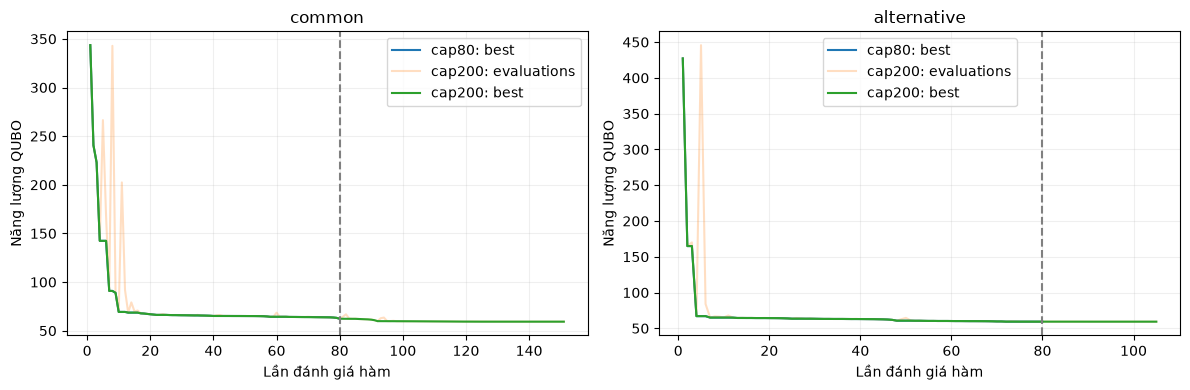

,start,best_E_first80_newrun,best_E_final,best_drop_last20,final_energy,stop
0,common,62.289841,59.293628,0.001668,59.293628,Return from COBYLA because the trust region ra...
1,alternative,59.319691,59.293624,0.016576,59.293624,Return from COBYLA because the trust region ra...


In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
tails=[]
for ax,row in zip(axes,rows):
    start=row["initial_point_id"]
    r=json.loads((ROOT/row["report"]).read_text(encoding="utf-8"))
    h=r["optimization_history"]; old=baseline_reports[start]["optimization_history"]
    e=np.array([x["estimated_qubo_energy"] for x in h]); best=np.minimum.accumulate(e)
    ax.plot(range(1,len(old)+1),np.minimum.accumulate([x["estimated_qubo_energy"] for x in old]),label="cap80: best")
    ax.plot(range(1,len(e)+1),e,alpha=.25,label="cap200: evaluations")
    ax.plot(range(1,len(e)+1),best,label="cap200: best")
    ax.axvline(80,color="grey",linestyle="--")
    ax.set(title=start,xlabel="Lần đánh giá hàm",ylabel="Năng lượng QUBO")
    ax.grid(alpha=.2);ax.legend()
    tails.append(dict(start=start,best_E_first80_newrun=float(best[min(79,len(best)-1)]),
        best_E_final=float(best[-1]),best_drop_last20=float(best[max(0,len(best)-21)]-best[-1]),
        final_energy=row["exact_mean_qubo_energy"],stop=row["optimizer_message"]))
fig.tight_layout();plt.show()
display(pd.DataFrame(tails))
campaign["budget_comparison"]=comparisons
campaign["tail_progress"]=tails
save_campaign(MANIFEST_PATH,campaign)

## Bước 9 — Quy tắc đọc kết quả và quyết định tiếp

- Nếu vẫn hết 200 lần đánh giá: chỉ kết luận **chưa đạt tiêu chuẩn dừng trong ngân sách**, không gọi là hội tụ hay bất khả thi. Xem tiến bộ cuối trước khi cân nhắc thêm ngân sách.
- Nếu dừng theo ngưỡng vùng tìm kiếm: đã dừng số học ở cấu hình đó; chưa chứng minh cực tiểu toàn cục hoặc giới hạn tốt nhất của p=1.
- Nếu E giảm và P_opt cũng giảm/không tăng: ngân sách cải thiện mục tiêu năng lượng, chưa cải thiện chỉ số placement. Đây là cơ sở chọn thí nghiệm objective riêng (ví dụ CVaR), chưa phải bằng chứng phương pháp mới sẽ tốt hơn.
- Nếu E và P_opt cùng cải thiện: ghi kết quả theo từng khởi tạo, rồi quyết định đối chứng tiếp; hai lượt không chứng minh tính ổn định tổng quát.

Không tự chạy p=3, đổi penalty, đổi mixer hoặc quét nhiều khởi tạo trong notebook này. Ground state và placement tối ưu luôn được báo riêng.

Nguồn về điều kiện dừng COBYLA: https://docs.scipy.org/doc/scipy/reference/optimize.minimize-cobyla.html

In [9]:
for row in rows:
    print(row["arm_id"],"| nfev:",row["cost_function_evals"],"| success:",row["optimizer_success"])
    print(" ",row["optimizer_message"])
    print("  E_exact:",row["exact_mean_qubo_energy"],"| P_opt (%):",100*row["exact_optimal_probability"])
print("Đọc delta_E và delta_P_opt_pp cùng nhau; success không chứng nhận tối ưu toàn cục.")

exact_common | nfev: 151 | success: True
  Return from COBYLA because the trust region radius reaches its lower bound.
  E_exact: 59.293627997229294 | P_opt (%): 0.12577054491206338
exact_alternative | nfev: 105 | success: True
  Return from COBYLA because the trust region radius reaches its lower bound.
  E_exact: 59.29362364000676 | P_opt (%): 0.125774162617793
Đọc delta_E và delta_P_opt_pp cùng nhau; success không chứng nhận tối ưu toàn cục.


## Bước 10 — Xác nhận, đóng gói report và lưu notebook
Kết quả đủ nghĩa là 2/2 report hợp lệ, không bắt buộc có nghiệm trong shots hoặc chạy đủ 200 đánh giá.

**Save As** bản đã chạy thành `13_qaoa_exact_budget_choice_executed.ipynb`; giữ nguyên notebook mẫu để hash/resume ổn định. Gửi bản đã chạy và ZIP được in dưới đây. ZIP chứa manifest, 2 report, CSV; không có notebook vì cần lưu output cell cuối trước.

In [10]:
verified=verify_campaign(ROOT,campaign,design,bundle,reference)
assert len(verified)==campaign["planned_run_count"]==campaign["completed_run_count"]==2
assert campaign["remaining_run_keys"]==[]
assert all(r["objective_mode"]=="exact" and r["maxiter"]==200 and r["evaluation_seed"]!=r["seed"] for r in verified)
EXPORT_PATH=RESULT_DIR/f"exact_budget_choice_{campaign['campaign_id']}.zip"
with zipfile.ZipFile(EXPORT_PATH,"w",zipfile.ZIP_DEFLATED) as z:
    for path in [MANIFEST_PATH,COMPARISON_PATH]+[ROOT/r["report"] for r in verified]:
        z.write(path,path.relative_to(ROOT).as_posix())
print("PASS — p1_choice: 2/2 exact completed, cap 200, independent final sampling verified.")
print("Gửi ZIP:",EXPORT_PATH.relative_to(ROOT).as_posix())
print("Save As notebook có output: 13_qaoa_exact_budget_choice_executed.ipynb")

PASS — p1_choice: 2/2 exact completed, cap 200, independent final sampling verified.
Gửi ZIP: data/reference_results/phase4e_convergence_runs/exact_budget_choice_20261009T080323983169Z.zip
Save As notebook có output: 13_qaoa_exact_budget_choice_executed.ipynb
